
# Практическое задание №1

Проанализируйте данные о вакансиях на глобальном рынке труда в сфере ИИ в 2025 году.

[Источник](https://www.kaggle.com/datasets/bismasajjad/global-ai-job-market-and-salary-trends-2025)

В файле `ai_job_dataset.csv` содержаться следующие переменные:


- job_id: Unique identifier for each job posting
- job_title: Standardized job title	
- salary_usd:	Annual salary in USD	
- salary_currency:	Original salary currency	
- salary_local:	Salary in local currency **(такого вроде нет, это ошибка)**
- experience_level:	EN (Entry), MI (Mid), SE (Senior), EX (Executive)	
- employment_type:	FT (Full-time), PT (Part-time), CT (Contract), FL (Freelance)	
- company_location:	Country where company is located	
- company_size:	S (Small <50), M (Medium 50-250), L (Large >250)	
- employee_residence:	Country where employee resides	
- remote_ratio:	0 (No remote), 50 (Hybrid), 100 (Fully remote)	
- required_skills:	Top 5 required skills (comma-separated)	
- education_required:	Minimum education requirement	
- years_experience:	Required years of experience	
- industry:	Industry sector of the company	
- posting_date:	Date when job was posted	
- application_deadline:	Application deadline	
- job_description_length:	Character count of job description	
- benefits_score:	Numerical score of benefits package (1-10)	

In [36]:
import pandas as pd

df = pd.read_csv("ai_job_dataset.csv")

1. Опишите датасет (число наблюдений и переменных, пропущенных значений, типы данных, типы шкал переменных).


In [37]:
print(f"Наблюдений (вакансий): {df.shape[0]}")
print(f"Переменных: {df.shape[1]}")
print(f"Пропущенных ячеек: {df.isna().sum().sum()}")
print("Пропуски по столбцам:")
print(df.isna().sum())
print("\nТипы данных:")
print(df.dtypes.to_string())

Наблюдений (вакансий): 15000
Переменных: 19
Пропущенных ячеек: 0
Пропуски по столбцам:
job_id                    0
job_title                 0
salary_usd                0
salary_currency           0
experience_level          0
employment_type           0
company_location          0
company_size              0
employee_residence        0
remote_ratio              0
required_skills           0
education_required        0
years_experience          0
industry                  0
posting_date              0
application_deadline      0
job_description_length    0
benefits_score            0
company_name              0
dtype: int64

Типы данных:
job_id                     object
job_title                  object
salary_usd                  int64
salary_currency            object
experience_level           object
employment_type            object
company_location           object
company_size               object
employee_residence         object
remote_ratio                int64
required_skill

**Пояснение к 1-му пункту**<br>
В таблице 15 000 вакансий и 19 переменных; пропусков нет.

Шкалы переменных:

- Номинальная: `job_id` (не уверен, его обычно никуда не относят), `job_title`, `salary_currency`, `employment_type`, `company_location`, `employee_residence`, `required_skills` (список категорий, хранящийся строкой), `industry`, `company_name`. Это просто категория без какого-либо порядка. 

- Порядковая: `experience_level` (EN -> MI -> SE -> EX), `company_size` (S -> M -> L), `education_required` (Associate -> Bachelor -> Master -> PhD), `benefits_score` (оценка пакета льгот). В этих шкалах можно понять порядок и кто идет за кем.

- Отношений: `salary_usd`, `remote_ratio`, `years_experience`, `job_description_length`. У этих величин есть содержательный ноль, условно у remote_ratio - это процент работы на удаленке, то есть начинается с 0.

- Интервальная: `posting_date`, `application_deadline`. Тут разницу между датами можно измерить в днях, но отношение самих календарных дат нет.

2. Отобразите первые пять строк и последние три строки датасета.

In [38]:
pd.concat([df.head(), df.tail(3)]).style

,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.900000,Smart Analytics
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.200000,TechCorp Inc
2,AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,2025-03-18,2025-04-07,1974,9.400000,Autonomous Tech
3,AI00004,NLP Engineer,80215,USD,SE,FL,India,M,India,50,"Scala, SQL, Linux, Python",PhD,7,Consulting,2024-12-23,2025-02-24,1345,8.600000,Future Systems
4,AI00005,AI Consultant,54624,EUR,EN,PT,France,S,Singapore,100,"MLOps, Java, Tableau, Python",Master,0,Media,2025-04-15,2025-06-23,1989,6.600000,Advanced Robotics
14997,AI14998,NLP Engineer,189490,USD,EX,CT,South Korea,L,South Korea,50,"Scala, Spark, NLP",Associate,17,Manufacturing,2024-03-19,2024-05-02,1336,7.400000,AI Innovations
14998,AI14999,Head of AI,79461,EUR,EN,FT,Netherlands,M,Netherlands,0,"Java, Computer Vision, Python, TensorFlow",PhD,1,Real Estate,2024-03-22,2024-04-23,1935,5.600000,Smart Analytics
14999,AI15000,Computer Vision Engineer,56481,USD,MI,PT,Austria,S,Austria,50,"Scala, Azure, Deep Learning, GCP, Mathematics",PhD,2,Technology,2024-07-18,2024-08-10,2492,7.600000,AI Innovations


**Пояснения ко второму пункту**<br>
Я использовал [] - list, чтобы создать список датафреймов. То есть в 1 датафрейме у меня первые 5 строк, во втором - последние 3. Потом я использовал concat,  чтобы соединить из в 1 датафрейм и вывести

3. Установите идентификатор вакансии (job_id) как индекс строк.

In [39]:
df.set_index("job_id", inplace=True) #inplace = True -> чтобы именно модифицировать, а не создавать новый
print("Название индекса:", df.index.name)
print("Первые идентификаторы:\n")
pd.DataFrame(df.head()).style

Название индекса: job_id
Первые идентификаторы:



,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
job_id,,,,,,,,,,,,,,,,,,
AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.900000,Smart Analytics
AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.200000,TechCorp Inc
AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,2025-03-18,2025-04-07,1974,9.400000,Autonomous Tech
AI00004,NLP Engineer,80215,USD,SE,FL,India,M,India,50,"Scala, SQL, Linux, Python",PhD,7,Consulting,2024-12-23,2025-02-24,1345,8.600000,Future Systems
AI00005,AI Consultant,54624,EUR,EN,PT,France,S,Singapore,100,"MLOps, Java, Tableau, Python",Master,0,Media,2025-04-15,2025-06-23,1989,6.600000,Advanced Robotics


4. Выведите список названий столбцов таблицы.

In [40]:
df.columns.tolist()

['job_title',
 'salary_usd',
 'salary_currency',
 'experience_level',
 'employment_type',
 'company_location',
 'company_size',
 'employee_residence',
 'remote_ratio',
 'required_skills',
 'education_required',
 'years_experience',
 'industry',
 'posting_date',
 'application_deadline',
 'job_description_length',
 'benefits_score',
 'company_name']

**Пояснение к 4 пункту**<br>
`job_id` нету так как мы его сделали индексом в прошлом номере :)

5. Выведите информацию о проценте непустых ячеек в каждом столбце.

In [41]:
print(df.notna().mean() * 100)

job_title                 100.0
salary_usd                100.0
salary_currency           100.0
experience_level          100.0
employment_type           100.0
company_location          100.0
company_size              100.0
employee_residence        100.0
remote_ratio              100.0
required_skills           100.0
education_required        100.0
years_experience          100.0
industry                  100.0
posting_date              100.0
application_deadline      100.0
job_description_length    100.0
benefits_score            100.0
company_name              100.0
dtype: float64


**Пояснение к 5 пункту**<br>
.mean() - доля именно в каждом столбце, потом при помощи умножения на 100 мы переводим это в проценты

6. Выведите описательные статистики по столбцам, содержащим количественные данные.

In [42]:
df.describe()

,salary_usd,remote_ratio,years_experience,job_description_length,benefits_score
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,115348.965133,49.483333,6.253200,1503.314733,7.504273
std,60260.940438,40.812712,5.545768,576.127083,1.450870
min,32519.000000,0.000000,0.000000,500.000000,5.000000
25%,70179.750000,0.000000,2.000000,1003.750000,6.200000
50%,99705.000000,50.000000,5.000000,1512.000000,7.500000
75%,146408.500000,100.000000,10.000000,2000.000000,8.800000
max,399095.000000,100.000000,19.000000,2499.000000,10.000000


7. Переименуйте столбец "industry" в "industry_comp".

In [43]:
df.rename(columns={"industry":"industry_comp"},inplace=True)
df.columns.tolist()

['job_title',
 'salary_usd',
 'salary_currency',
 'experience_level',
 'employment_type',
 'company_location',
 'company_size',
 'employee_residence',
 'remote_ratio',
 'required_skills',
 'education_required',
 'years_experience',
 'industry_comp',
 'posting_date',
 'application_deadline',
 'job_description_length',
 'benefits_score',
 'company_name']

8. Выведите столбцы, характеризующие вознаграждение за работу.

In [44]:
df[["salary_usd", "salary_currency", "benefits_score"]]

,salary_usd,salary_currency,benefits_score
job_id,,,
AI00001,90376,USD,5.9
AI00002,61895,USD,5.2
AI00003,152626,USD,9.4
AI00004,80215,USD,8.6
AI00005,54624,EUR,6.6
...,...,...,...
AI14996,38604,USD,7.9
AI14997,57811,GBP,8.2
AI14998,189490,USD,7.4


**Поясенение к 8 пункту**<br>
Я добавил `benefits_score`, так как у нас вопрос именно про вознаграждение за работу, не факт, что денежное, поэтому этот столбец тоже подходит

9. Выведите название позиции для вакансии с идентификатором AI00056.

In [45]:
df.loc['AI00056', 'job_title']

'AI Architect'

10. Отобразите данные о вакансиях, в которых заработная плата выше 200000 долларов США.

In [46]:
df[df["salary_usd"] > 200_000]

,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry_comp,posting_date,application_deadline,job_description_length,benefits_score,company_name
job_id,,,,,,,,,,,,,,,,,,
AI00049,AI Specialist,288815,USD,EX,PT,Switzerland,S,Switzerland,0,"Deep Learning, Git, Data Visualization, Linux,...",Bachelor,12,Manufacturing,2024-08-08,2024-09-23,1930,7.2,Cognitive Computing
AI00068,Machine Learning Engineer,316182,USD,EX,PT,Denmark,M,Canada,0,"Python, Scala, Statistics, Git",Associate,12,Finance,2025-02-09,2025-02-23,2452,7.0,Digital Transformation LLC
AI00077,AI Product Manager,213783,USD,EX,FT,Canada,S,Canada,100,"Kubernetes, Spark, Statistics, Scala",Bachelor,16,Energy,2024-09-19,2024-10-06,2383,9.2,Quantum Computing Inc
AI00080,AI Research Scientist,284486,USD,EX,CT,United States,M,United States,0,"PyTorch, Linux, SQL",Master,12,Consulting,2025-02-13,2025-03-10,2231,7.0,TechCorp Inc
AI00083,Machine Learning Researcher,207548,USD,EX,CT,Canada,M,Canada,0,"NLP, Azure, Spark, Data Visualization",PhD,10,Energy,2024-02-05,2024-03-11,2292,6.7,Cognitive Computing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AI14964,AI Architect,238571,USD,EX,FT,Singapore,S,Singapore,50,"Hadoop, Java, Deep Learning",PhD,11,Government,2024-03-09,2024-04-09,573,9.0,Cognitive Computing
AI14969,Robotics Engineer,233563,USD,EX,FT,Sweden,M,Sweden,100,"Linux, NLP, SQL, GCP, R",Master,18,Energy,2025-01-24,2025-02-27,2400,5.2,DataVision Ltd
AI14978,Research Scientist,325968,USD,EX,CT,Norway,M,Israel,100,"Python, Spark, MLOps, Computer Vision, Deep Le...",Associate,10,Technology,2024-07-17,2024-09-13,1514,9.8,Quantum Computing Inc


11. Создайте новый столбец, в котором размер заработной платы рассчитан в рублях по текущему курсу.

In [47]:
usd_to_rub = 84.0954 # на момент 22.09
df["salary_rub"] = (df["salary_usd"] * usd_to_rub).round(2)
pd.DataFrame(df[["salary_usd", "salary_rub"]].head()).style.format({"salary_rub": "{:.2f}"})

,salary_usd,salary_rub
job_id,,
AI00001,90376,7600205.87
AI00002,61895,5205084.78
AI00003,152626,12835144.52
AI00004,80215,6745712.51
AI00005,54624,4593627.13


12. Создайте новый столбец is_local, который будет иметь значение True, если company_location == employee_residence, и False в противном случае.

In [48]:
df["is_local"] = df["company_location"] == df["employee_residence"]
pd.DataFrame(df[["company_location", "employee_residence", "is_local"]].head()).style

,company_location,employee_residence,is_local
job_id,,,
AI00001,China,China,True
AI00002,Canada,Ireland,False
AI00003,Switzerland,South Korea,False
AI00004,India,India,True
AI00005,France,Singapore,False


13. Рассчитайте средние заработные платы для вакансий с различными требованиями к опыту кандидатов.

In [49]:
pd.DataFrame(df.groupby("experience_level")["salary_usd"].mean()).style.format({"salary_usd": "{:.2f}"})

,salary_usd
experience_level,
EN,63133.38
EX,187723.65
MI,87955.47
SE,122187.66


14. Рассчитайте минимальные заработные платы для различных должностей для компаний разного размера (в одной таблице). 

In [50]:
df.pivot_table("salary_usd", index='job_title', columns='company_size', aggfunc='min').style

company_size,L,M,S
job_title,,,
AI Architect,41846,36338,33220
AI Consultant,42570,36071,33959
AI Product Manager,42239,36162,33770
AI Research Scientist,42869,36574,33092
AI Software Engineer,42835,36152,33013
AI Specialist,41740,36553,34174
Autonomous Systems Engineer,42185,36197,32790
Computer Vision Engineer,42189,36732,32519
Data Analyst,41634,36523,32542


15. Рассчитайте медиану требуемого опыта работы в годах для вакансий в китайских компаниях с требованием уровня образования не ниже магистерского.

In [51]:
med = df[(df["company_location"] == "China") & (df["education_required"].isin(["Master", "PhD"]))]
med["years_experience"].median()

5.0

16. Постройте гистограммы трех различных метрических переменных и опишите их. Столбики первой гистограммы должны быть красного цвета, второй - синего, третьей - зеленого.

<AxesSubplot: title={'center': 'Зарплата, USD в год'}, ylabel='Frequency'>

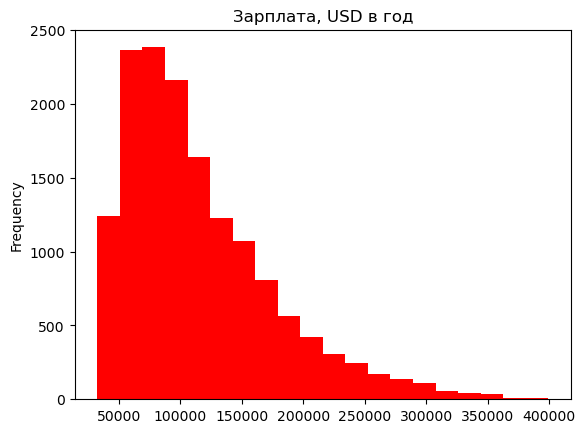

In [52]:
df["salary_usd"].plot.hist(bins=20, color="red", title="Зарплата, USD в год")


<AxesSubplot: title={'center': 'Требуемый опыт, лет'}, ylabel='Frequency'>

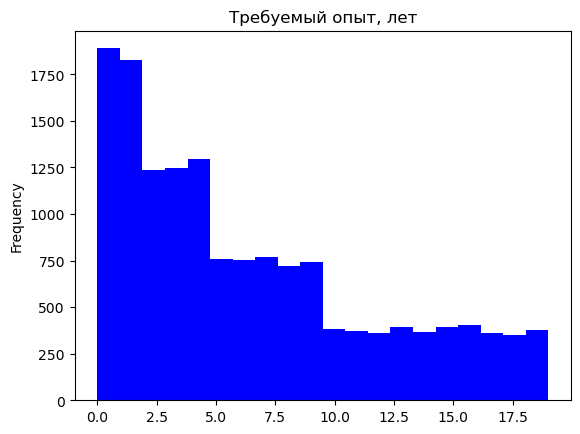

In [53]:
df["years_experience"].plot.hist(bins=20, color="blue", title="Требуемый опыт, лет")

<AxesSubplot: title={'center': 'Доля удалённой работы, %'}, ylabel='Frequency'>

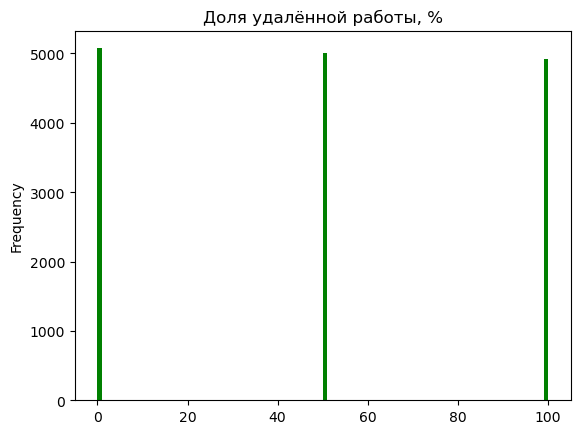

In [54]:
df["remote_ratio"].plot.hist(
    bins=100, color="green", title="Доля удалённой работы, %"
)

17. Постройте диаграмму, демонстрирующую взаимосвязь между размером компании и заработной платой. Добавьте название диаграмме и подписи осям. Обоснуйте выбор диаграммы и прокомментируйте тенденции и взаимосвязи, которые на ней отображены.

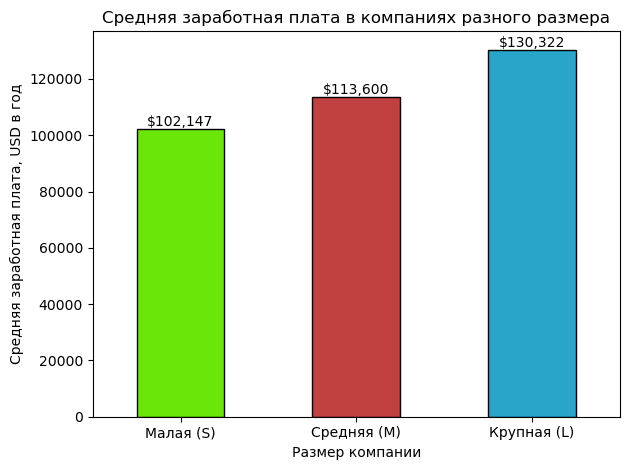

In [55]:
salary_by_company_size = (
    df.groupby("company_size")["salary_usd"]
    .mean()
    .reindex(["S", "M", "L"])       # <-- сделал, чтобы компании шли по возрастанию, так лучше смотрится просто
)

ax = salary_by_company_size.plot(
    kind="bar", color=["#6AE708", "#C14040", "#28a5c9"], edgecolor="black"
)
ax.set_title("Средняя заработная плата в компаниях разного размера")
ax.set_xlabel("Размер компании")
ax.set_ylabel("Средняя заработная плата, USD в год")
ax.set_xticklabels(["Малая (S)", "Средняя (M)", "Крупная (L)"], rotation=0)
ax.bar_label(
    ax.containers[0], labels=[f"${value:,.0f}" for value in salary_by_company_size]  # <- эта штука из matplotlib чтобы были подписи на каждом столбце, также использовал 
)                                                                                    # f-строки для корректного и красивого отображение средней зп
ax.figure.tight_layout()

**Пояснение к 17 пункту**<br>
 Столбчатая диаграмма подходит для сравнения средней количественной величины между несколькими категориями (в нашем случае средней ЗП в разных компаниях). Я расположил их в более удобном для человека порядке - по возврастанию размера компании.<br>

 Средняя годовая зарплата последовательно растёт с размером компании, ~ с 102,1 тыс. долларов до 113,6 тыс. долларов в средних и 130,3 тыс. долларов в крупных. Из графика видно, что в среднем, чем больше компания, тем большую ЗП она готова предоставить. Разница между крупными и малыми компаниями составляет около 28,2 тыс. долларов или 27,6%.<br>

 P.S. Но график все еще очень абстрактный и показывает в целом разницу в ЗП. На уровень оплаты также могут влиять должность, опыт работы,
  страна, отрасль и другие характеристики вакансии. Для более содержательного сравнения следует рассматривать похожие вакансии в компаниях разного размера, учитывая разные факторы.

18. Постройте ящичковую диаграмму заработной платы. Наблюдаются ли выбросы?

Первый квартиль: 70179.75
Третий квартиль: 146408.50
Межквартильный размах: 76228.75
Нижняя граница: -44163.38
Верхняя граница: 260751.62 <-- отрицательная, а так как мы работаем с ЗП, значит нижней граница 0
Количество выбросов: 483


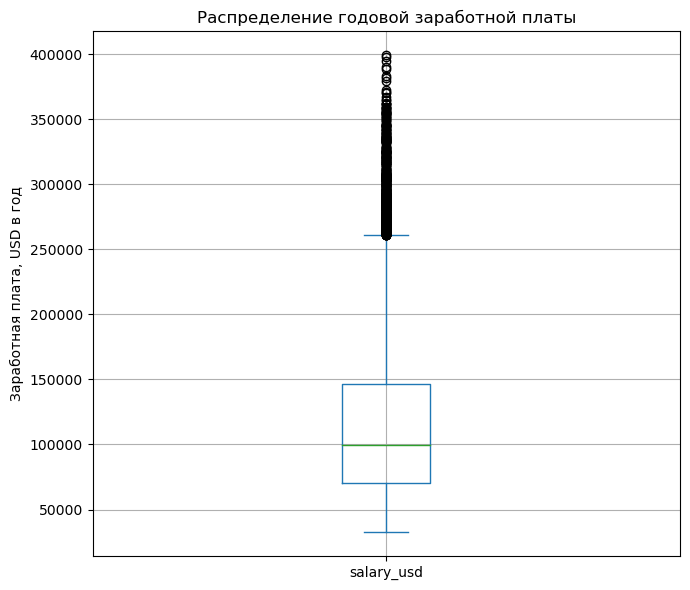

In [56]:
ax = df["salary_usd"].plot.box(
    figsize=(7, 6),
    title="Распределение годовой заработной платы",
      ylabel="Заработная плата, USD в год",
    grid=True
  )

ax.figure.tight_layout()

q1 = df["salary_usd"].quantile(0.25)
q3 = df["salary_usd"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = df[
    (df["salary_usd"] < lower) |
    (df["salary_usd"] > upper)
]
print(f"Первый квартиль: {q1:.2f}")
print(f"Третий квартиль: {q3:.2f}")
print(f"Межквартильный размах: {iqr:.2f}")
print(f"Нижняя граница: {lower:.2f}")
print(f"Верхняя граница: {upper:.2f} <-- отрицательная, а так как мы работаем с ЗП, значит нижней граница 0")
print(f"Количество выбросов: {len(outliers)}")

**Пояснение к 18му пункту**<br>
  Ящичковая диаграмма позволяет оценить распределение заработной платы, её медиану, межквартильный размах, наличие выбросов и тд. Границы выбросов я выбрал по правилу 1,5 межквартильного размаха (Обсуждалось еще на 1 семинаре).

  Первый квартиль заработной платы составляет 70,2 тыс. долларов, а третий 146,4 тыс. долларов. Следовательно, межквартильный размах равен 76,2 тыс. долларов. Верхняя граница, после которой значения считаются выбросами, составляет приблизительно 260,8 тыс. долларов.

  Исходя из тех данных, что за пределами наших границ, получается 483 выброса - это вакансии с годовой заработной платой выше 260,8 тыс. долларов. Они составляют около 3,2% всех наблюдений. Нижних выбросов нет, так как рассчитанная нижняя граница отрицательная , а мы работаем с ЗП, которая отрицательной быть не может.

19. Определите топ-5 стран по количеству вакансий. Визуализируйте это с помощью столбчатой диаграммы.

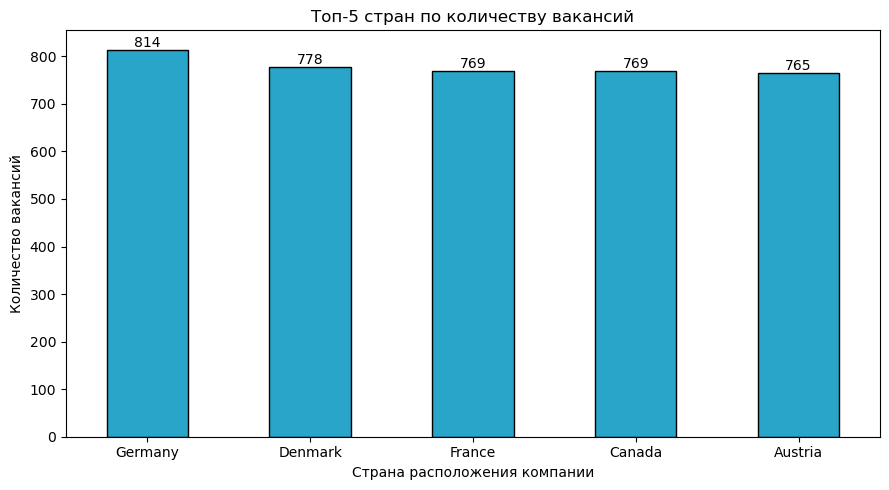

In [57]:
top_5_countries = df["company_location"].value_counts().head()

ax = top_5_countries.plot.bar(
    figsize=(9, 5),
    color="#28a5c9",
    edgecolor="black",
    title="Топ-5 стран по количеству вакансий",
    xlabel="Страна расположения компании",
    ylabel="Количество вакансий",
    rot=0,
)
ax.bar_label(
    ax.containers[0],
    labels=top_5_countries,
)
ax.figure.tight_layout()

20. Как связаны формат работы и зарплата? Кто получает больше — офисные, гибридные или полностью удалённые работники? Отличаются ли эти тенденции по странам?

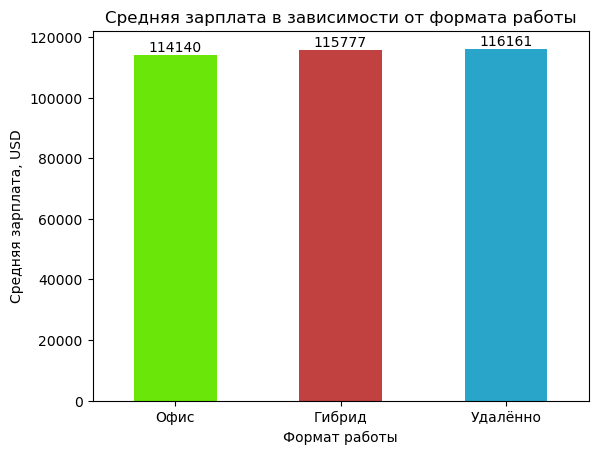

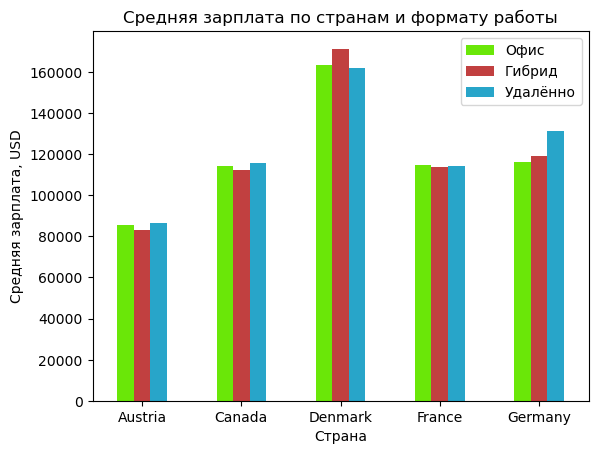

In [58]:
salary_remote = df.groupby("remote_ratio")["salary_usd"].mean()
salary_remote.index = ["Офис", "Гибрид", "Удалённо"]

ax1 = salary_remote.plot.bar(
    color=["#6AE708", "#C14040", "#28a5c9"],
    title="Средняя зарплата в зависимости от формата работы",
    xlabel="Формат работы",
    ylabel="Средняя зарплата, USD",
    rot=0
)
ax1.bar_label(ax1.containers[0], fmt="%.0f")

top_countries = df["company_location"].value_counts().head().index
salary_country = df[df["company_location"].isin(top_countries)].pivot_table(
    index="company_location",
    columns="remote_ratio",
    values="salary_usd",
    aggfunc="mean"
)
salary_country.columns = ["Офис", "Гибрид", "Удалённо"]

ax2 = salary_country.plot.bar(
    color=["#6AE708", "#C14040", "#28a5c9"],
    title="Средняя зарплата по странам и формату работы",
    xlabel="Страна",
    ylabel="Средняя зарплата, USD",
    rot=0
)

**Пояснение к 20му пункту**<br>
значение `remote_ratio` = 0 это полноценная работа в офисе, = 50 - гибрид, а = 100  это полностью удаленная работа. 
Самая высокая средняя зарплата у полностью удалённых работников ~ 116,2 тыс. долларов в год. У гибридных работников она составляет около 115,8 тыс. долларов, а у офисных ~ 114 тыс. долларов, поэтому я считаю, что формат работы слабо влияет на ЗП.<br>
По странам результаты сильно различаются. Я взял самые популярные страны среди датасета. В Германии, Канаде и Австрии больше предлагают удалённым работникам, в Дании - работникам с гибридным форматом, а во Франции, что не удивительно, офисным. Поэтому достаточно трудно найти какую - то корреляцию, но если судить по количеству, то бОльшую Зп предлагают всё таки удалённым сотрудникам.

21. Насколько часто место расположения компании и место проживания сотрудника не совпадают? Влияет ли это на зарплату?

Место расположения не совпадает у 4256 вакансий
Доля несовпадений: 28.4%


[Text(0, 0, '116282'), Text(0, 0, '114979')]

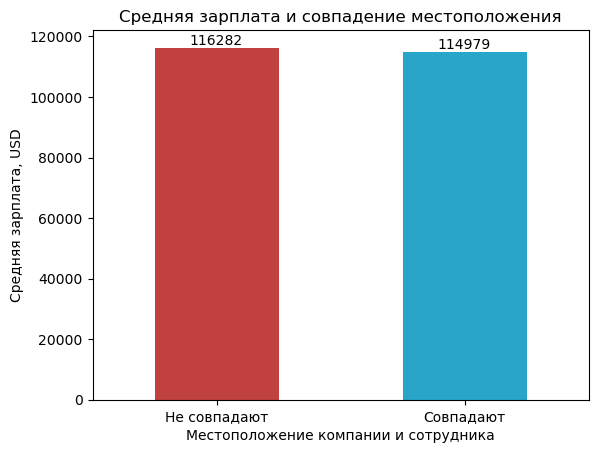

In [59]:
mismatch_count = (df["is_local"] == False).sum()
mismatch_percent = (df["is_local"] == False).mean() * 100
print(f"Место расположения не совпадает у {mismatch_count} вакансий")
print(f"Доля несовпадений: {mismatch_percent:.1f}%")
salary_location = df.groupby("is_local")["salary_usd"].mean()
salary_location.index = ["Не совпадают", "Совпадают"]
ax = salary_location.plot.bar(
    color=["#C14040", "#28a5c9"],
    title="Средняя зарплата и совпадение местоположения",
    xlabel="Местоположение компании и сотрудника",
    ylabel="Средняя зарплата, USD",
    rot=0
)
ax.bar_label(ax.containers[0], fmt="%.0f")

**Пояснение к 21-му пункту**<br>Место расположения компании и место проживания сотрудника не совпадают в 4256 вакансиях, то есть в 28,4% случаев. При несовпадении средняя зарплата составляет около 116,3 тыс. долларов, а при совпадении - ~ 115 тыс. долларов. Разница равна примерно 1%, поэтому заметного влияния совпадения местоположения на зарплату нет.

22. Охарактеризуйте распределение требуемого опыта работы для каждой профессии.

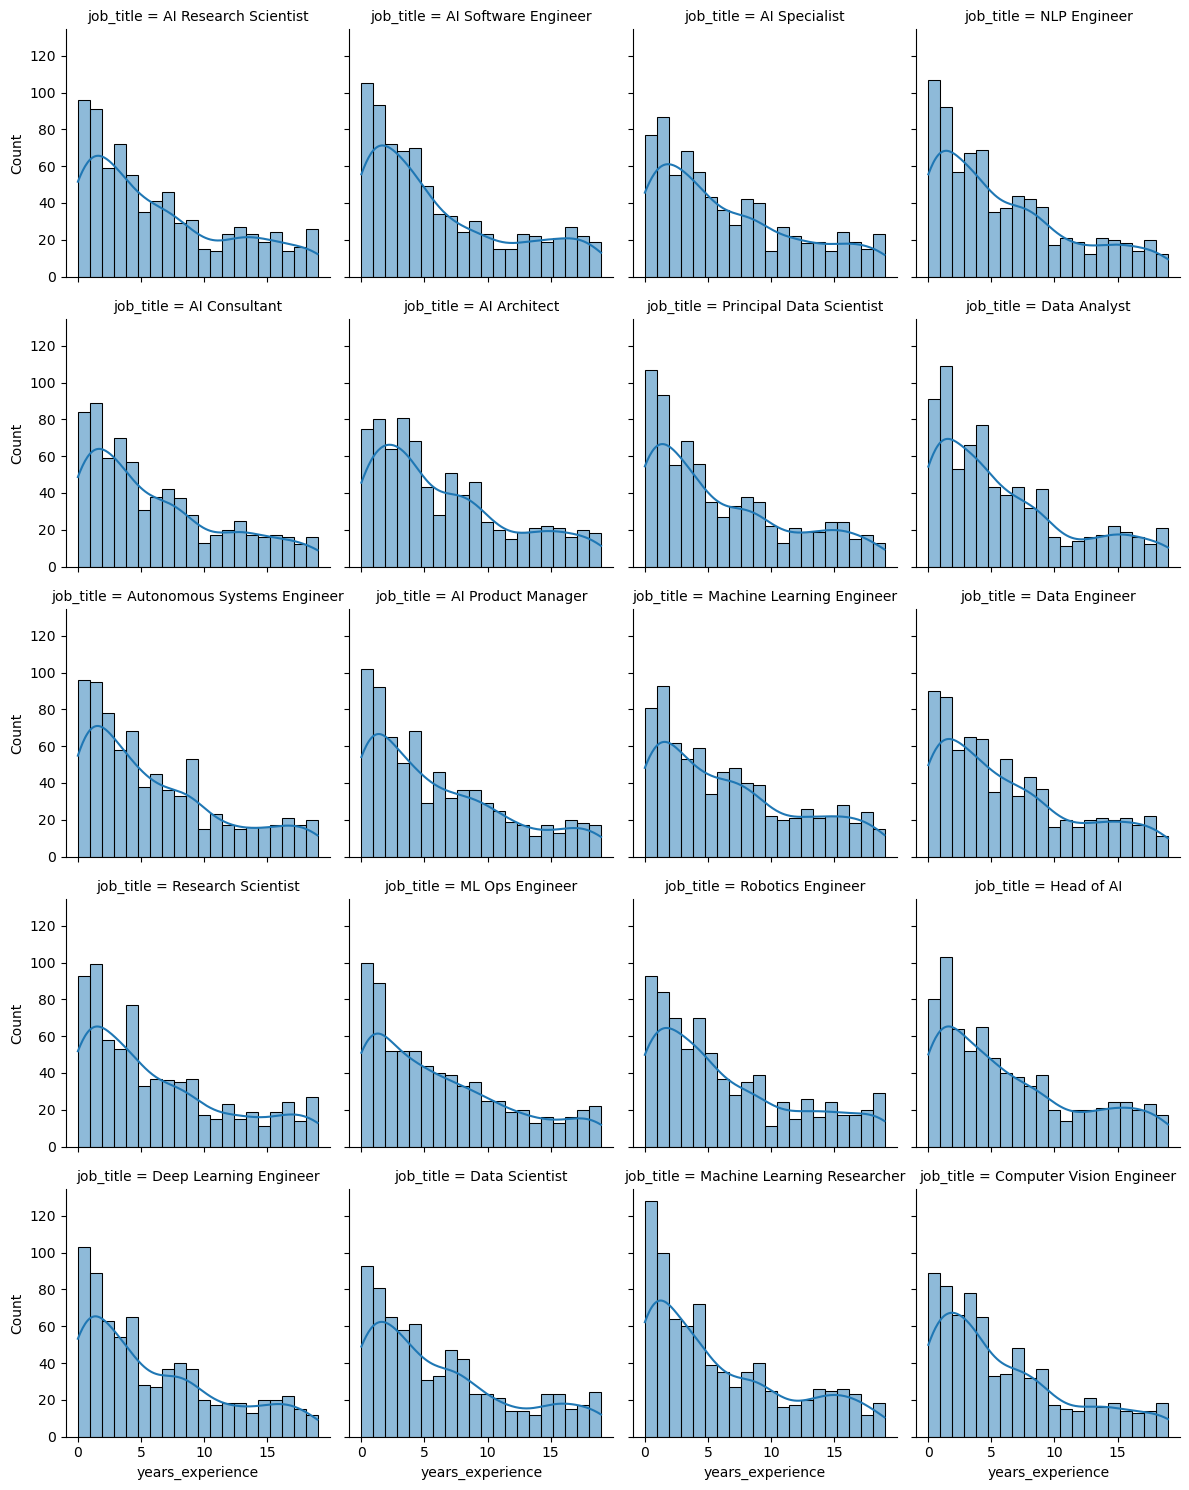

In [60]:
import seaborn as sns

sns.displot(data=df, x = "years_experience", col="job_title", bins = 20, kde = True, height = 3,col_wrap = 4); 

**Пояснение к 22-му пункту**<br>
Из графиков в целом видно, что распределение опыта имеет правостороннюю ассиметрию, то есть больше всего вакансий требует именно небольшого срока работы до 5-6 лет. Причем у некоторых профессий есть 'вторые пики' примерно в 7-10 лет опыта, к примеру AI Specialist.

23. Есть ли взаимосвязь между числом символов в описании вакансии и зарплатой?

Корреляция: -0.009


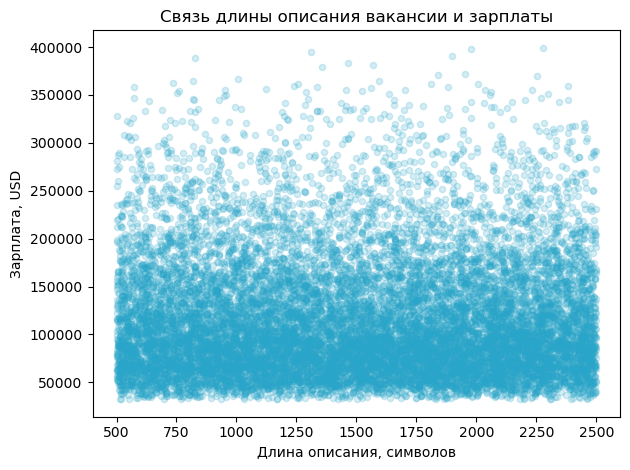

In [61]:
description_salary_corr = df["job_description_length"].corr(df["salary_usd"],method="pearson")
print(f"Корреляция: {description_salary_corr:.3f}")

ax = df.plot.scatter(
    x="job_description_length",
    y="salary_usd",
    alpha=0.2,
    color="#28a5c9",
    title="Связь длины описания вакансии и зарплаты",
    xlabel="Длина описания, символов",
    ylabel="Зарплата, USD"
)
ax.figure.tight_layout()

**Пояснение к 23-му пункту**<br>
Я взял коэффициент корреляции Пирсона (так как лучше всего понимаю как он работает:)).
Коэффициент корреляции между числом символов в описании вакансии и ЗП равен -0,009, что очень близко к нулю. На диаграмме также не видно выраженной связи. Поэтому корреляция почти отсутвует.

24. Визуализируйте распределение вакансий по месяцам (posting_date). Какие тенденции наблюдаются?

[Text(0, 1, '953'),
 Text(0, 1, '927'),
 Text(0, 1, '932'),
 Text(0, 1, '985'),
 Text(0, 1, '955'),
 Text(0, 1, '938'),
 Text(0, 1, '959'),
 Text(0, 1, '958'),
 Text(0, 1, '895'),
 Text(0, 1, '949'),
 Text(0, 1, '922'),
 Text(0, 1, '959'),
 Text(0, 1, '964'),
 Text(0, 1, '840'),
 Text(0, 1, '922'),
 Text(0, 1, '942')]

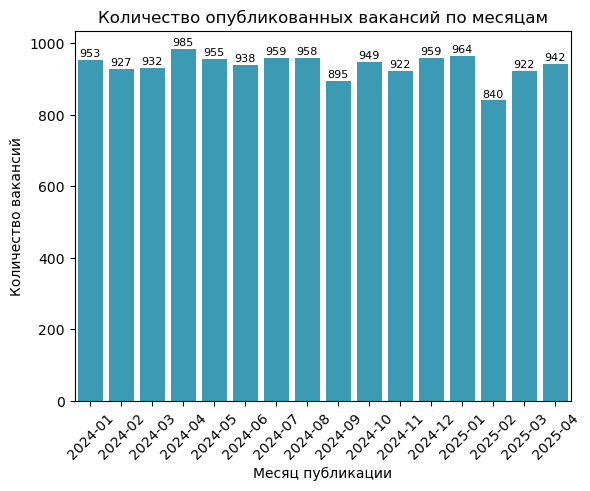

In [62]:
import seaborn as sns
df["posting_date"] = pd.to_datetime(df["posting_date"])

vacancies_by_month = df.groupby(df["posting_date"].dt.to_period("M")).size().reset_index(name="vacancies")
vacancies_by_month["posting_date"] = vacancies_by_month["posting_date"].astype(str)
ax = sns.barplot(data=vacancies_by_month, x = "posting_date", y="vacancies",color="#28a5c9"); 
ax.set_title("Количество опубликованных вакансий по месяцам")
ax.set_xlabel("Месяц публикации")
ax.set_ylabel("Количество вакансий")
ax.tick_params(axis="x", rotation=45)
ax.bar_label(
    ax.containers[0],
    padding=1,
    fontsize=8
)

**Пояснение к 24-му пункту**<br>
Количество опубликованных вакансий по месяцам меняется незначительно и в основном находится в пределах от 900 до 1000. Больше всего вакансий было опубликовано в апреле 2024 года - 985, меньше всего в феврале 2025 года - 840. Однако есть ежегодное снижение в феврале, которое может быть связано с меньшим количеством дней в этом месяце. Также январь постоянно в топе самых популярных месяцев, что может быть связанно с новогодними праздниками).

25. Рассчитайте временную разницу между posting_date и application_deadline. Влияет ли она на зарплату?

,application_period
count,15000.00
mean,43.55
std,17.33
min,14.00
25%,29.00
50%,44.00
75%,59.00
max,74.00


Корреляция с зарплатой: 0.013


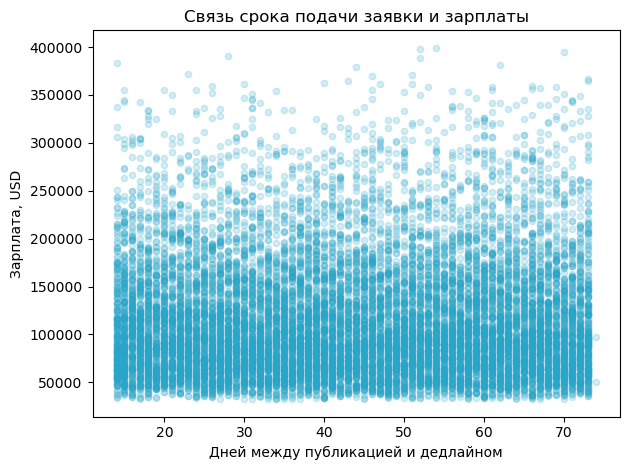

In [63]:
df["application_deadline"] = pd.to_datetime(df["application_deadline"])
df["application_period"] = (
    df["application_deadline"] - df["posting_date"]
).dt.days

display(pd.DataFrame(df["application_period"].describe()).style.format({"application_period": "{:.2f}"}))

deadline_salary_corr = df["application_period"].corr(df["salary_usd"],method="pearson")
print(f"Корреляция с зарплатой: {deadline_salary_corr:.3f}")
ax = df.plot.scatter(
    x="application_period",
    y="salary_usd",
    alpha=0.2,
    color="#28a5c9",
    title="Связь срока подачи заявки и зарплаты",
    xlabel="Дней между публикацией и дедлайном",
    ylabel="Зарплата, USD",
)
ax.figure.tight_layout()

**Пояснение к 25-му пункту**<br>
В среднем между публикацией вакансии и дедлайном проходит 43,6 дней, а медиана - 44 дня. Минимальный период составляет 14 дней, максимальный - 74 дня. Корреляция срока подачи заявки с зарплатой равна 0,013 и снова практически не отличается от нуля, также по графику видно, что связи почти нету.

26. Как сочетаются education_required и years_experience? Требуется ли больше лет опыта при меньшем образовании?

,count,mean,median,min,max
education_required,,,,,
Associate,3785,6.21,4.00,0,19
Bachelor,3789,6.30,5.00,0,19
Master,3748,6.45,5.00,0,19
PhD,3678,6.05,4.00,0,19


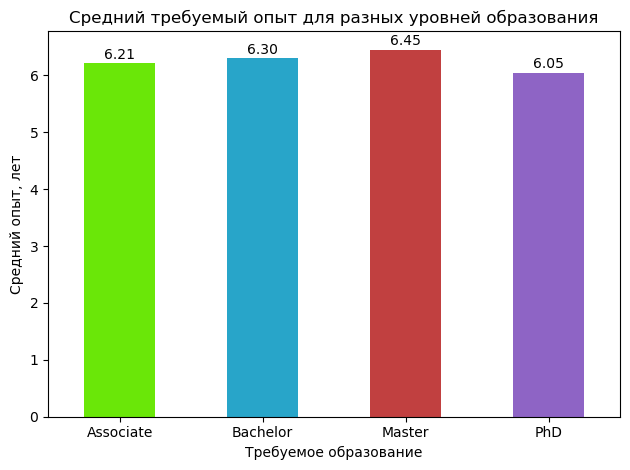

In [64]:
education_experience = (
    df.groupby("education_required")["years_experience"]
    .agg(["count", "mean", "median", "min", "max"])
    .reindex(["Associate", "Bachelor", "Master", "PhD"])
    .round(2)
)
display(pd.DataFrame(education_experience).style.format({"mean": "{:.2f}", "median": "{:.2f}"}))

ax = education_experience["mean"].plot.bar(
    color=["#6AE708", "#28a5c9", "#C14040", "#8E64C5"],
    title="Средний требуемый опыт для разных уровней образования",
    xlabel="Требуемое образование",
    ylabel="Средний опыт, лет",
    rot=0
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=1)
ax.figure.tight_layout()

**Пояснение к 26-му пункту**<br>
Средний требуемый опыт почти не различается между уровнями образования. Для Associate он равен 6,21 года, для Bachelor = 6,30, для Master = 6,45, а для PhD = 6,05 года. Последовательного увеличения опыта при снижении уровня образования нет, обратного тоже.

27. Опишите профиль вакансий с самыми высокими заработными платами (самостоятельно установите критерии отнесения зарплат к высоким). Что наиболее востребовано на таких вакансиях? Отличаются ли требования к кандидатам с самыми высокими зарплатами по странам?

In [65]:
high_salary_limit = df["salary_usd"].quantile(0.90)
high_salary = df[df["salary_usd"] >= high_salary_limit]

print(f"НИжняя граница высокой зарплаты: {high_salary_limit:.0f} $")
print(f"Количество высокооплачиваемых вакансий: {len(high_salary)}")
print(f"Средний требуемый опыт: {high_salary['years_experience'].mean():.1f} лет\n")

print("Самые оплачиваемые вакансии:")
display(pd.DataFrame(high_salary["job_title"].value_counts().head()).style)
print("\nНеобходимый опыт:")
display(pd.DataFrame(high_salary["experience_level"].value_counts()).style)
print("\nТребуемое образование:")
display(pd.DataFrame(high_salary["education_required"].value_counts()).style)

# Чтобы посчитать скиллы и их частоту вхождения в заявки надо сначала очистить данные,
# так как все скиллы нам даны в виде списка, надо убрать сначала все запятые и пробелы (при помощи split, strip и explode)
top_skills = (
    high_salary["required_skills"]
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head()
)
print("\nСамые востребованные скиллы:")
display(pd.DataFrame(top_skills).style)

# берем самые популярные страны
top_countries = high_salary["company_location"].value_counts().head().index
rows = []
for country in top_countries:
    # отбираем все вакансии в каждой из самых популярных стран поочередно
    jobs = high_salary[high_salary["company_location"] == country]

    top_skills = (
        jobs["required_skills"]
        .str.split(",")
        .explode()
        .str.strip()
        .value_counts()
        .head(3)
    )
    rows.append(
        {
            "country": country,
            "vacancies": len(jobs),
            "exp_level": jobs["experience_level"].value_counts().index[0],
            "mean_exp": jobs["years_experience"].mean(),
            "education": jobs["education_required"].value_counts().index[0],
            "skills": ", ".join(
                f"{skill} : {count} " for skill, count in top_skills.items()
            ),
        }
    )
print("\nТребования по самым популярным странам:")
display(pd.DataFrame(rows).style.format({"mean_exp": "{:.2f}"}))

НИжняя граница высокой зарплаты: 199217 $
Количество высокооплачиваемых вакансий: 1500
Средний требуемый опыт: 13.9 лет

Самые оплачиваемые вакансии:


,count
job_title,
Head of AI,94
Machine Learning Engineer,93
Principal Data Scientist,86
Robotics Engineer,85
AI Research Scientist,84



Необходимый опыт:


,count
experience_level,
EX,1390
SE,110



Требуемое образование:


,count
education_required,
Bachelor,396
Master,391
Associate,364
PhD,349



Самые востребованные скиллы:


,count
required_skills,
Python,441
SQL,323
Scala,301
TensorFlow,294
PyTorch,280



Требования по самым популярным странам:


,country,vacancies,exp_level,mean_exp,education,skills
0,Denmark,226,EX,13.42,Master,"Python : 77 , SQL : 50 , TensorFlow : 47"
1,Switzerland,214,EX,12.42,Associate,"Python : 68 , TensorFlow : 57 , Scala : 50"
2,Norway,184,EX,13.59,Master,"Python : 59 , SQL : 41 , Kubernetes : 40"
3,United States,151,EX,14.25,Bachelor,"Python : 37 , Java : 37 , PyTorch : 36"
4,Netherlands,104,EX,14.77,Master,"Python : 26 , Data Visualization : 22 , SQL : 21"


**Пояснение к 27-му пункту**<br>
К высоким я отнёс зарплаты, входящие в верхние 10% выборки. Нижняя граница высокой ЗП составляет примерно 199,2 тыс. долларов в год. Всего таких вакансий 1500.<br>

Для высокооплачиваемых вакансий в среднем требуется 13,9 года опыта. Почти все они рассчитаны на руководящие должности EX, 1390 вакансий из 1500. Чаще всего встречаются вакансии Head of AI, Machine Learning Engineer и Principal Data Scientist. Среди навыков наиболее востребованы Python, SQL, Scala, TensorFlow и PyTorch. <br>

Требования по странам немного отличаются. Средний требуемый опыт среди пяти лидирующих стран находится ~ от 12,4 до 14,8 лет. Однако требование к образованию разное, в США это Bachelor, а в Дании, Норвегии и Нидерландах - Master. При этом во всех пяти странах чаще всего требуется уровень опыта EX, а также главный скилл везде - Python. Количество вакансий тоже (может показаться, что от размера страны, но Дания ломает это предположение, она точно не больше США, но кол-во вакансий там наибольшее), от 104 в Нидерландах до 226 в Дании.

**Доп анализ**<br>
Связь зп по уровню опыта и размер компании

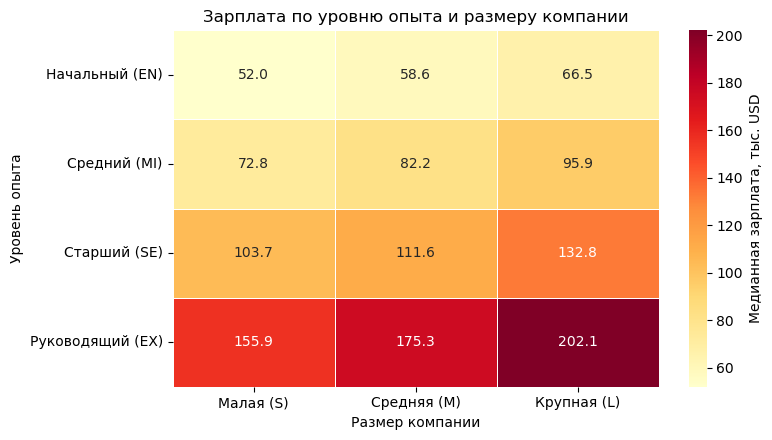

In [67]:
import seaborn as sns

levels = ["EN", "MI", "SE", "EX"]
sizes = ["S", "M", "L"]

med_salary = (
    df.pivot_table(
        index="experience_level",
        columns="company_size",
        values="salary_usd",
        aggfunc="median",
    )
    .reindex(index=levels, columns=sizes)
)

ax = sns.heatmap(
    med_salary / 1000,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Медианная зарплата, тыс. USD"},
)
ax.figure.set_size_inches(8, 4.5)
ax.set_title("Зарплата по уровню опыта и размеру компании")
ax.set_xlabel("Размер компании")
ax.set_ylabel("Уровень опыта")
ax.set_xticklabels(["Малая (S)", "Средняя (M)", "Крупная (L)"], rotation=0)
ax.set_yticklabels(["Начальный (EN)", "Средний (MI)", "Старший (SE)", "Руководящий (EX)"], rotation=0)
ax.figure.tight_layout()

**Вывод по тепловой карте.**<br>
Медианная зарплата повышается от начального уровня (EN) к руководящему (EX) при любом размере компании. 
Внутри каждого уровня опыта она также различает, так для EN это 52,0 тыс. USD в малых и 66,5 тыс. USD в крупных, 
для EX это 155,9 и 202,1 тыс. USD соответственно.
Поэтому и опыт и размер компании влияет на ЗП.

**Комментарии к заданию и принципам его оценивания:**

 - Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
 - Если Вы получили результаты в виде статистических показателей, таблиц или графиков, при этом никак их не прокомментировали и не сформулировали содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
 - Если Вы полностью выполнили это задание, то получаете за него 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение инструментов описательного анализа и их применение, или развернутое и глубокое исследование имеющихся данных на основе использования пройденных на занятиях инструментов.
 - Задание можно выполнять индивидуально или в группе из 2 человек, критерии оценивания при этом не меняются;
 - В названии загружаемого в Smart LMS файла нужно указать фамилию(ии) автора(ов) работы.
 - При использовании инструментов искусственного интеллекта необходимо отметить это в работе в соответствии с правилами НИУ ВШЭ.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и загрузить в Smart LMS до 21:00 4 октября.